# Spotify Dataset EDA

A short first look at the Spotify tracks dataset used for this project. The notebook checks the data, summarizes the audio features, and plots a few simple patterns.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("data/data.csv")
tracks = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Rows: {len(tracks):,} | Columns: {len(tracks.columns)}")
tracks.head()

Rows: 170,653 | Columns: 19


,valence,year,acousticness,artists,danceability,duration_ms,energy,explicit,id,instrumentalness,key,liveness,loudness,mode,name,popularity,release_date,speechiness,tempo
0,0.0594,1921,0.982,"['Sergei Rachmaninoff', 'James Levine', 'Berli...",0.279,831667,0.211,0,4BJqT0PrAfrxzMOxytFOIz,0.878000,10,0.665,-20.096,1,"Piano Concerto No. 3 in D Minor, Op. 30: III. ...",4,1921,0.0366,80.954
1,0.9630,1921,0.732,['Dennis Day'],0.819,180533,0.341,0,7xPhfUan2yNtyFG0cUWkt8,0.000000,7,0.160,-12.441,1,Clancy Lowered the Boom,5,1921,0.4150,60.936
2,0.0394,1921,0.961,['KHP Kridhamardawa Karaton Ngayogyakarta Hadi...,0.328,500062,0.166,0,1o6I8BglA6ylDMrIELygv1,0.913000,3,0.101,-14.850,1,Gati Bali,5,1921,0.0339,110.339
3,0.1650,1921,0.967,['Frank Parker'],0.275,210000,0.309,0,3ftBPsC5vPBKxYSee08FDH,0.000028,5,0.381,-9.316,1,Danny Boy,3,1921,0.0354,100.109
4,0.2530,1921,0.957,['Phil Regan'],0.418,166693,0.193,0,4d6HGyGT8e121BsdKmw9v6,0.000002,3,0.229,-10.096,1,When Irish Eyes Are Smiling,2,1921,0.0380,101.665


## Columns and types

Check the available fields before choosing features for the recommender.

In [2]:
tracks.info()

<class 'pandas.DataFrame'>
RangeIndex: 170653 entries, 0 to 170652
Data columns (total 19 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   valence           170653 non-null  float64
 1   year              170653 non-null  int64  
 2   acousticness      170653 non-null  float64
 3   artists           170653 non-null  str    
 4   danceability      170653 non-null  float64
 5   duration_ms       170653 non-null  int64  
 6   energy            170653 non-null  float64
 7   explicit          170653 non-null  int64  
 8   id                170653 non-null  str    
 9   instrumentalness  170653 non-null  float64
 10  key               170653 non-null  int64  
 11  liveness          170653 non-null  float64
 12  loudness          170653 non-null  float64
 13  mode              170653 non-null  int64  
 14  name              170653 non-null  str    
 15  popularity        170653 non-null  int64  
 16  release_date      170653 non-nu

## Missing values and duplicate rows

In [3]:
missing = tracks.isna().sum().sort_values(ascending=False)
missing[missing > 0].head(12), tracks.duplicated().sum()

(Series([], dtype: int64), np.int64(0))

## Audio feature summaries

These are the numeric track properties planned for the similarity model.

In [4]:
audio_features = [
    "valence", "acousticness", "danceability", "duration_ms", "energy",
    "instrumentalness", "liveness", "loudness", "speechiness", "tempo",
]
audio_features = [column for column in audio_features if column in tracks.columns]
tracks[audio_features].describe().round(2)

,valence,acousticness,danceability,duration_ms,energy,instrumentalness,liveness,loudness,speechiness,tempo
count,170653.00,170653.00,170653.00,170653.00,170653.00,170653.00,170653.00,170653.00,170653.00,170653.00
mean,0.53,0.50,0.54,230948.31,0.48,0.17,0.21,-11.47,0.10,116.86
std,0.26,0.38,0.18,126118.41,0.27,0.31,0.17,5.70,0.16,30.71
min,0.00,0.00,0.00,5108.00,0.00,0.00,0.00,-60.00,0.00,0.00
25%,0.32,0.10,0.42,169827.00,0.26,0.00,0.10,-14.62,0.03,93.42
50%,0.54,0.52,0.55,207467.00,0.47,0.00,0.14,-10.58,0.04,114.73
75%,0.75,0.89,0.67,262400.00,0.70,0.10,0.26,-7.18,0.08,135.54
max,1.00,1.00,0.99,5403500.00,1.00,1.00,1.00,3.86,0.97,243.51


## Feature distributions

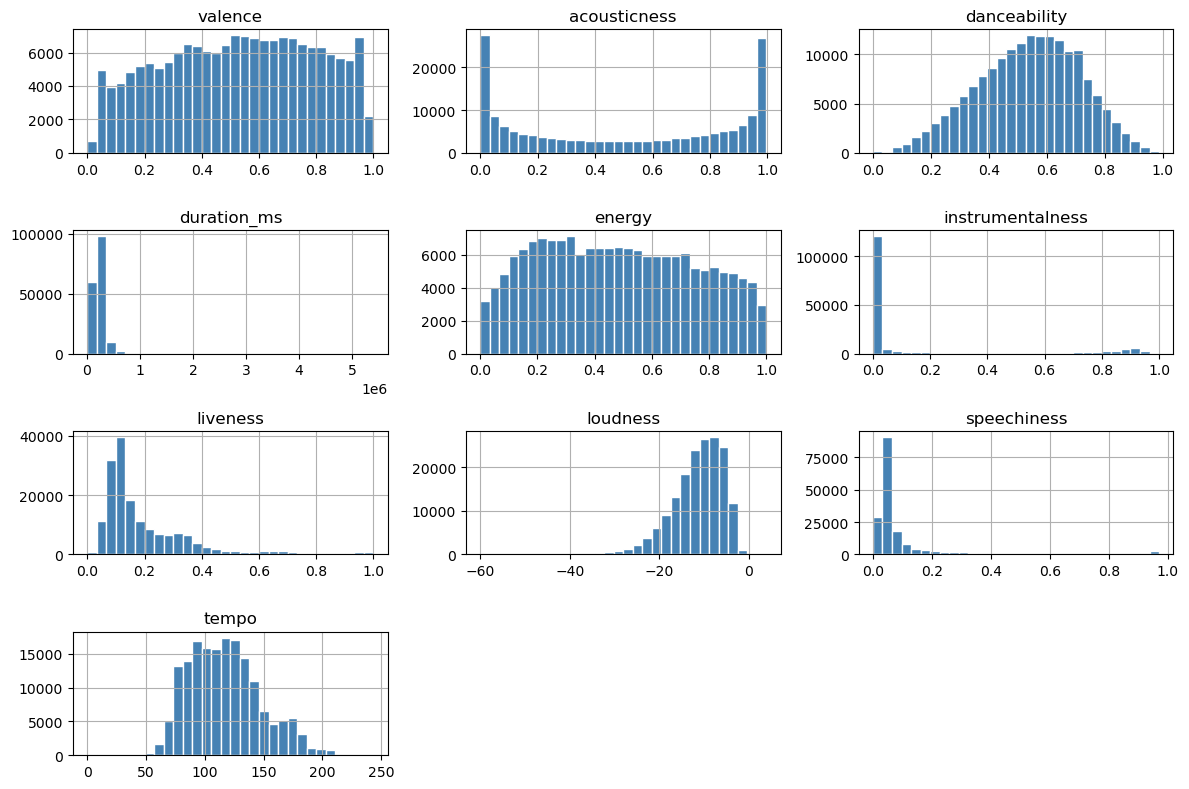

In [5]:
tracks[audio_features].hist(figsize=(12, 8), bins=30, color="steelblue", edgecolor="white")
plt.tight_layout()
plt.show()

## Tracks by release year

The dataset includes older releases as well as recent tracks. This chart shows how many rows appear for each year.

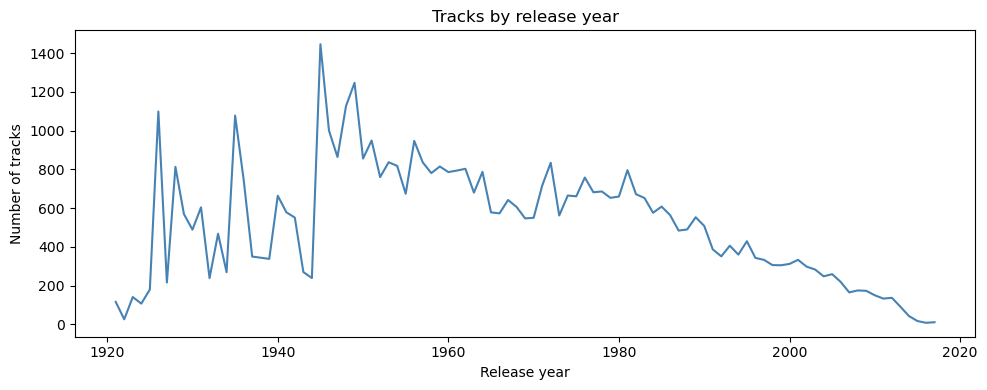

In [6]:
if "release_date" in tracks.columns:
    year = pd.to_datetime(tracks["release_date"], errors="coerce").dt.year
    yearly_counts = year.value_counts().sort_index()
    yearly_counts.plot(figsize=(10, 4), color="steelblue")
    plt.title("Tracks by release year")
    plt.xlabel("Release year")
    plt.ylabel("Number of tracks")
    plt.tight_layout()
    plt.show()
else:
    print("No release_date column was found.")

## A few most common artists

Artist names are stored as list-like text in this dataset, so this quick count uses the first listed artist.

In [7]:
artist_column = "artists" if "artists" in tracks.columns else "artist"
if artist_column in tracks.columns:
    lead_artist = tracks[artist_column].astype(str).str.extract(r"([A-Za-z0-9][^,]*)")[0].str.strip()
    print(lead_artist.value_counts().head(10))
else:
    print("No artist column was found.")

0
Francisco Canaro'           1285
Frédéric Chopin'            1016
Francisco Canaro']           942
Wolfgang Amadeus Mozart'     920
Johann Sebastian Bach'       900
Ludwig van Beethoven'        886
Frank Sinatra']              630
Ignacio Corsini']            628
Giuseppe Verdi'              593
Igor Stravinsky'             569
Name: count, dtype: int64


## Takeaway

The audio columns provide a compact description of each track. They can be scaled and compared to find similar songs. Genre tags are artist-level metadata, so they can add context but may not describe every individual track precisely.